## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import setup

Total combinations of features: 1023


## Setup

In [4]:
VERSION = 3
RANDOM_SEED = 1

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/classification/_<VAR_X>/cut_*/*'
METRIC = 'test_auc'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(405, 29)

In [6]:
df_results.columns

Index(['strategy_id', 'features_id', 'y', 'features', 'nfeatures',
       'cat_features', 'best_params', 'best_score', 'best_iteration',
       'test_size', 'random_state', 'loss_function', 'eval_metric',
       'train_eval', 'test_accuracy', 'test_f1', 'test_precision',
       'test_recall', 'test_auc', 'all_accuracy', 'all_f1', 'all_precision',
       'all_recall', 'all_auc', 'f_name', 'labels', 'y_test', 'y_pred',
       'y_pred_proba'],
      dtype='object')

In [7]:
cols = ['y','features_id','strategy_id','train_eval','test_accuracy','all_accuracy','test_f1','test_precision','test_recall','test_auc','all_auc','f_name']
df_results[cols].sort_values(METRIC, ascending=False)

,y,features_id,strategy_id,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name
314,gender_median,49,4,0.536183,0.818182,0.813253,0.819311,0.830769,0.822727,0.958540,0.928376,median_49_4
248,gender_median,51,4,0.552093,0.818182,0.795181,0.819311,0.830769,0.822727,0.957091,0.926270,median_51_4
261,gender_median,50,4,0.586885,0.818182,0.777108,0.819311,0.830769,0.822727,0.955713,0.920038,median_50_4
306,gender_median,72,4,0.124957,0.848485,0.849398,0.848297,0.853030,0.850505,0.955371,0.947982,median_72_4
318,gender_median,45,4,0.513024,0.848485,0.789157,0.848297,0.853030,0.850505,0.953966,0.929755,median_45_4
...,...,...,...,...,...,...,...,...,...,...,...,...
86,gender_mean,5,3,0.914804,0.515152,0.536145,0.226667,0.171717,0.333333,0.635931,0.646859,mean_5_3
31,gender_mean,5,1,1.039528,0.468750,0.463855,0.358289,0.352657,0.426573,0.610582,0.598165,mean_5_1
209,gender_mean,5,2,1.048202,0.437500,0.439759,0.351909,0.315620,0.439394,0.603535,0.603425,mean_5_2
396,gender_mode,5,5,1.016496,0.454545,0.469880,0.355061,0.292754,0.452381,0.596355,0.598172,mode_5_5


In [8]:
best_id = df_results[METRIC].idxmax()
best_id

314

In [9]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_f1','test_auc']]

,y,features,train_eval,test_f1,test_auc
314,gender_median,"[mean_ngender_rn, mean_ngender_rw]",0.536183,0.819311,0.95854


In [10]:
df_results.loc[best_id].features

['mean_ngender_rn', 'mean_ngender_rw']

In [11]:
df_results.loc[best_id].strategy_id, setup.STRATEGY[df_results.loc[best_id].strategy_id]

(4, {'cuts': [0.3, 0.7], 'gt_agg': 'median'})

In [12]:
df_results.loc[best_id]

strategy_id                                                       4
features_id                                                      49
y                                                     gender_median
features                         [mean_ngender_rn, mean_ngender_rw]
nfeatures                                                         2
cat_features                                                     []
best_params       {'depth': 2, 'learning_rate': 0.05, 'l2_leaf_r...
best_score        {'learn': {'MultiClass': 0.5361831091759522}, ...
best_iteration                                                   99
test_size                                                       0.2
random_state                                                      1
loss_function                                            MultiClass
eval_metric                                              MultiClass
train_eval                                                 0.536183
test_accuracy                                   

In [13]:
metric = df_results.loc[best_id].y.replace('gender_','')
cut_id = df_results.loc[best_id].strategy_id
gt_agg = setup.STRATEGY[df_results.loc[best_id].strategy_id]['gt_agg']

f_name = DIR.replace('<VAR_X>', metric).replace('cut_*/*', f"cut_{cut_id}")
f_name = f"{f_name}/{metric}_{df_results.loc[best_id].features_id}_{df_results.loc[best_id].strategy_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs1/classification/_median/cut_4/median_49_4'

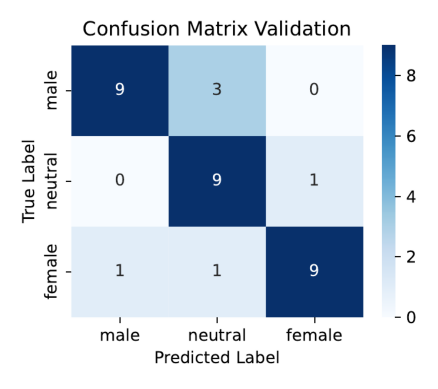

In [14]:
# predictions
fn = f"{f_name}_confusion_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



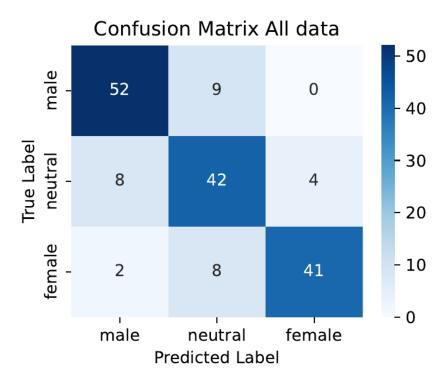

In [15]:
# predictions
fn = f"{f_name}_confusion_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



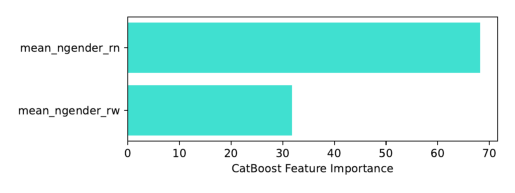

In [16]:
# predictors
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

